# 模块 3：导航纯算法示例

本 notebook 直接复用 `navigator.py`，展示航迹选择、`Waypoint`/`PositionCommand`、短时保持和 0.5 s 超时悬停。不导入 ROS 或 MAVROS 消息。

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'navigator.py').is_file():
    root = root.parent
assert (root / 'code' / 'navigator.py').is_file(), '未找到项目根目录'
sys.path.insert(0, str(root / 'code'))

from datatypes import Pose, Track
from navigator import on_timer, select_track, send_waypoint, waypoints_from_track

def track(track_id, position, age):
    return Track(track_id, position, (0.0, 0.0, 0.0), (0.0,) * 36, age)

## 1. 航迹选择与位置指令

选择 `age` 最大者，并在同龄时选 `id` 最小者。算法返回纯 `PositionCommand`。

In [2]:
tracks = [
    track(8, (8.0, 1.0, 3.0), age=4),
    track(3, (3.0, -2.0, 5.0), age=9),
    track(1, (1.0, 7.0, 2.0), age=9),
]
selected = select_track(tracks)
waypoint = waypoints_from_track(selected)[0]
command = send_waypoint(waypoint)
print('selected track:', selected.id, 'age=', selected.age)
print('waypoint      :', waypoint)
print('command       :', command)
assert selected.id == 1
assert command.coordinate_frame == 1 and command.type_mask == 3576

selected track: 1 age= 9
waypoint      : Waypoint(position=(1.0, 7.0, 2.0), yaw=0.0)
command       : PositionCommand(coordinate_frame=1, type_mask=3576, position=(1.0, 7.0, 2.0), velocity=(0.0, 0.0, 0.0), yaw=0.0, yaw_rate=0.0)


## 2. 50 Hz 时钟层的三种输出

`on_timer` 本身不依赖时钟；节点以 50 Hz 调用它，并传入距最后非空输入的秒数。

In [3]:
pose = Pose(position=(20.0, 30.0, 6.0), orientation=(0.0, 0.0, 0.0, 1.0))
fresh = on_timer(tracks, valid_age=0.0, last_cmd=None, current_pose=pose)
held = on_timer([], valid_age=0.30, last_cmd=fresh, current_pose=pose)
hover = on_timer([], valid_age=0.51, last_cmd=fresh, current_pose=pose)
print('fresh target :', fresh.position)
print('short hold   :', held.position)
print('timeout hover:', hover.position)
assert held == fresh
assert hover.position == pose.position
assert hover.coordinate_frame == 1 and hover.type_mask == 3576

fresh target : (1.0, 7.0, 2.0)
short hold   : (1.0, 7.0, 2.0)
timeout hover: (20.0, 30.0, 6.0)


## 3. 边界：无航迹且无可保持指令

此时直接根据最新 `Pose` 生成悬停指令。

In [4]:
empty = on_timer([], valid_age=float('inf'), last_cmd=None, current_pose=pose)
print(empty)
assert empty.position == (20.0, 30.0, 6.0)

PositionCommand(coordinate_frame=1, type_mask=3576, position=(20.0, 30.0, 6.0), velocity=(0.0, 0.0, 0.0), yaw=0.0, yaw_rate=0.0)


## 4. 效果图：航迹选择与超时悬停

俯视图展示三种输出的空间关系：雷达航迹点、选中航点，以及断流超过 0.5 s 后回到当前位姿的悬停点。

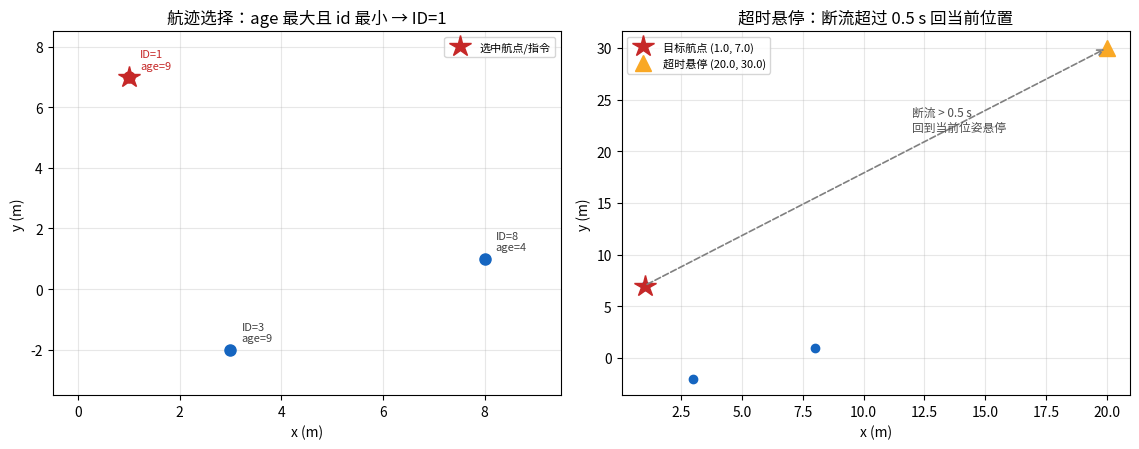

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'navigator.py').is_file():
    root = root.parent
assert (root / 'code' / 'navigator.py').is_file(), '未找到项目根目录'
if str(root / 'code') not in sys.path:
    sys.path.insert(0, str(root / 'code'))

%matplotlib inline
import matplotlib.pyplot as plt

from datatypes import Pose, Track
from navigator import select_track, send_waypoint, waypoints_from_track, hover_setpoint

plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

def track(track_id, position, age):
    return Track(track_id, position, (0.0, 0.0, 0.0), (0.0,) * 36, age)

tracks = [
    track(8, (8.0, 1.0, 3.0), age=4),
    track(3, (3.0, -2.0, 5.0), age=9),
    track(1, (1.0, 7.0, 2.0), age=9),
]
pose = Pose(position=(20.0, 30.0, 6.0), orientation=(0.0, 0.0, 0.0, 1.0))
selected = select_track(tracks)
waypoint = waypoints_from_track(selected)[0]
command = send_waypoint(waypoint)
hover = hover_setpoint(pose)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

ax = axes[0]
for tr in tracks:
    is_selected = tr.id == selected.id
    ax.plot(tr.position[0], tr.position[1], 'o', ms=8,
            color='#c62828' if is_selected else '#1565c0', zorder=3)
    ax.annotate('ID=%d\nage=%d' % (tr.id, tr.age),
                (tr.position[0], tr.position[1]),
                textcoords='offset points', xytext=(8, 6), fontsize=8,
                color='#c62828' if is_selected else '0.25')
ax.plot(command.position[0], command.position[1], '*', ms=16, color='#c62828',
        label='选中航点/指令', zorder=4)
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('航迹选择：age 最大且 id 最小 → ID=1')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_xlim(-0.5, 9.5)
ax.set_ylim(-3.5, 8.5)

ax = axes[1]
for tr in tracks:
    ax.plot(tr.position[0], tr.position[1], 'o', ms=6, color='#1565c0')
ax.plot(command.position[0], command.position[1], '*', ms=16, color='#c62828',
        label='目标航点 (%.1f, %.1f)' % (command.position[0], command.position[1]))
ax.plot(hover.position[0], hover.position[1], '^', ms=12, color='#f9a825',
        label='超时悬停 (%.1f, %.1f)' % (hover.position[0], hover.position[1]))
ax.annotate('', xy=(hover.position[0], hover.position[1]),
            xytext=(command.position[0], command.position[1]),
            arrowprops=dict(arrowstyle='->', color='0.5', lw=1.2, linestyle='--'))
ax.text(12.0, 22.0, '断流 > 0.5 s\n回到当前位姿悬停', fontsize=8.5, color='0.3')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('超时悬停：断流超过 0.5 s 回当前位置')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()